In [1]:
import mlflow
import json

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("hw-04-wum")
mlflow.start_run()


<ActiveRun: >

In [2]:
from datetime import datetime
start_time = datetime.now()
mlflow.log_param("start_time", start_time.isoformat() + "Z")

dataset_name = "wum-dataset-hw"
min_support = 0.001
min_confidence = 0.2
min_visit_length_pages = 2
min_visit_length_seconds = 1
preprocessing_method = "transaction_matrix"



mlflow.log_param("dataset_name", dataset_name)
mlflow.log_param("min_support", min_support)
mlflow.log_param("min_confidence", min_confidence)
mlflow.log_param("min_visit_length_pages", min_visit_length_pages)
mlflow.log_param("min_visit_length_seconds", min_visit_length_seconds)
mlflow.log_param("preprocessing_method", preprocessing_method)

'transaction_matrix'

## Preprocess

In [3]:
import pandas as pd

clicks = pd.read_csv("../resources/wum_dataset_hw/clicks.csv")

# drop page ids, local ids, cat ids and so on
clicks = clicks[
    [
        "VisitID",
        "SequenceNumber",
        "PageName",
        "CatName",
        "ExtCatName",
        "TopicName",
        "TimeOnPage",
    ]
]

def normalize(x):
    if pd.isna(x):
        return ""
    y = str(x).strip().upper()
    y = y.replace(" ", "_")
    return y

for col in ["PageName", "CatName", "ExtCatName", "TopicName"]:
    clicks[col] = clicks[col].apply(normalize)

# sort to preserve navigation order sequence, strip string and replace spaces with _
clicks = clicks.sort_values(["VisitID", "SequenceNumber"])

visitors = pd.read_csv("../resources/wum_dataset_hw/visitors.csv")
visitors = visitors[(visitors["Length_pagecount"] >= 2) & (visitors["Length_seconds"] > 0)]
valid_ids = set(visitors["VisitID"])

clicks = clicks[clicks["VisitID"].isin(valid_ids)]


## Create transactions matrix

In [4]:
# identify conversions from PageName
PAGE_TO_APRIORI_CONVERSION = {
    "APPLICATION": "VIEW_APPLICATION", # macro conversions
    "CATALOG": "VIEW_CATALOG",

    "INSURANCE": "VIEW_INSURANCE", # micro conversions
    "DISCOUNT": "VIEW_DISCOUNT",
    "WHOWEARE": "VIEW_WHOWEARE",
    "HOWTOJOIN": "VIEW_HOWTOJOIN",

    "LASTMINUTE": "VIEW_LASTMINUTE"
}

# internal only
CONVERSION_TO_FEATURE = {
    "VIEW_APPLICATION": "Has_APPLICATION",
    "VIEW_INSURANCE": "Has_INSURANCE",
    "VIEW_DISCOUNT": "Has_DISCOUNT",
    "VIEW_CATALOG": "Has_CATALOG",
    "VIEW_WHOWEARE": "Has_WHOWEARE",
    "VIEW_HOWTOJOIN": "Has_HOWTOJOIN",
    "VIEW_LASTMINUTE": "Has_LASTMINUTE",
}

In [5]:
# extracts conversions and interaction used as items in transaction
def process_session(session):
    items = set()

    topics = set()

    # store to make count queries easier later
    features = {}

    search_count = 0
    page_count = len(session)

    for page, cat, ext, topic, time in session:

        # remove those which don't add meaningful information
        if topic not in {"IN_GENERAL", "UNDETECTED", "NENI", "LASTMINUTE", ""}:
            topics.add(topic)

        # how many searches was done
        if cat == "SEARCH":
            search_count += 1

        # identify conversions from PageName
        mapped = None

        # using only pages as cat names don't include all (at least HOWTOJOIN)
        if page in PAGE_TO_APRIORI_CONVERSION:
            mapped = PAGE_TO_APRIORI_CONVERSION[page]

        if mapped:
            items.add(mapped)
            feature_key = CONVERSION_TO_FEATURE[mapped]
            features[feature_key] = 1

    # flush identified topics
    for t in topics:
        items.add(f"TOPIC_{t}")

    # store user behaviour features
    for n in reversed(range(1, 9)):
        if len(topics) >= n:
            items.add(f"TOPICS>={n}")
            break

    for n in reversed(range(1, 9)):
        if search_count >= n:
            items.add(f"SEARCH>={n}")
            break

    features["SearchCount"] = search_count
    features["PageCount"] = page_count
    features["TopicCount"] = len(topics)


    return items, features

In [6]:
def build_sessions(df):
    return list(zip(
        df["PageName"],
        df["CatName"],
        df["ExtCatName"],
        df["TopicName"],
        df["TimeOnPage"]
    ))

sessions = clicks.groupby("VisitID").apply(build_sessions, include_groups=False)
sessions.reset_index(name='actions')
sessions

VisitID
1186     [(NORWAY_JOURNEY_TO_THE_FAR_NORTH_LOFOTEN, TRI...
1187     [(TRAVELAGENCY, INFO, HOMEPAGE, IN_GENERAL, 30...
1189     [(TRAVELAGENCY, INFO, HOMEPAGE, IN_GENERAL, 60...
1190     [(N_NEWS_TRIPS, INFO, SENDS_NEWS, IN_GENERAL, ...
1192     [(TRAVELAGENCY, INFO, HOMEPAGE, IN_GENERAL, 30...
                               ...                        
17255    [(TRAVELAGENCY, INFO, HOMEPAGE, IN_GENERAL, 30...
17257    [(TRAVELAGENCY, INFO, HOMEPAGE, IN_GENERAL, 60...
17260    [(TRAVELAGENCY, INFO, HOMEPAGE, IN_GENERAL, 30...
17264    [(BULGARIA_STAY_WITH_HOLIDAY_TRIPS_05, TRIP, U...
17265    [(TRAVELAGENCY, INFO, HOMEPAGE, IN_GENERAL, 30...
Length: 5542, dtype: object

### Filter out transactions with only element and create rules

In [7]:
transaction_list = []
feature_rows = []

for visit_id, session in sessions.items():
    items, features = process_session(session)
    transaction_list.append(
        {"VisitId": visit_id, "items": items}
    )

    features["VisitID"] = visit_id
    feature_rows.append(features)

transactions_df = pd.DataFrame(transaction_list)
features_df = pd.DataFrame(feature_rows)
# filter those having only element
transactions = [t["items"] for t in transaction_list]
transactions = [
    t for t in transactions
    if len(t) > 1
]

In [8]:
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)

df_onehot = pd.DataFrame(te_array, columns=te.columns_)

In [9]:
from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(
    df_onehot,
    min_support=min_support,
    use_colnames=True
)

In [10]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=min_confidence
)
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(TOPICS>=1),(SEARCH>=1),0.458837,0.370754,0.272309,0.593476,1.600725,1.0,0.102193,1.547867,0.693475,0.488636,0.353950,0.663974
1,(SEARCH>=1),(TOPICS>=1),0.370754,0.458837,0.272309,0.734472,1.600725,1.0,0.102193,2.038064,0.596401,0.488636,0.509338,0.663974
2,(TOPICS>=2),(SEARCH>=1),0.282096,0.370754,0.058530,0.207483,0.559624,1.0,-0.046058,0.793984,-0.522929,0.098482,-0.259471,0.182675
3,(TOPIC_BULGARIA),(SEARCH>=1),0.070620,0.370754,0.018998,0.269022,0.725607,1.0,-0.007184,0.860827,-0.289213,0.044980,-0.161674,0.160132
4,(TOPIC_CORSICA),(SEARCH>=1),0.104970,0.370754,0.025331,0.241316,0.650879,1.0,-0.013587,0.829391,-0.374723,0.056242,-0.205703,0.154820
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38315,"(SEARCH>=8, TOPIC_TOURISM, TOPIC_HOTELBUSES)","(TOPIC_STAYS_WITH_TRIPS, TOPIC_TOURS_WITH_ACCO...",0.004414,0.002687,0.001151,0.260870,97.099379,1.0,0.001140,1.349306,0.994089,0.193548,0.258878,0.344720
38316,"(TOPIC_TOURISM, TOPIC_TOURS_WITH_LIGHTWEIGHT_T...","(TOPIC_STAYS_WITH_TRIPS, SEARCH>=8, TOPIC_TOUR...",0.004414,0.004414,0.001151,0.260870,59.103970,1.0,0.001132,1.346970,0.987439,0.150000,0.257593,0.260870
38317,"(SEARCH>=8, TOPIC_TOURS_WITH_LIGHTWEIGHT_TOURI...","(TOPIC_STAYS_WITH_TRIPS, TOPIC_TOURISM, TOPIC_...",0.002879,0.003070,0.001151,0.400000,130.275000,1.0,0.001143,1.661549,0.995189,0.240000,0.398152,0.387500
38318,"(TOPIC_TOURISM, TOPIC_TOURS_WITH_LIGHTWEIGHT_T...","(TOPIC_STAYS_WITH_TRIPS, SEARCH>=8, TOPIC_TOUR...",0.005373,0.003454,0.001151,0.214286,62.035714,1.0,0.001133,1.268331,0.989195,0.150000,0.211562,0.273810


In [11]:
rules_catalog = rules[
    rules["consequents"].apply(lambda x: "VIEW_CATALOG" in x)
]


rules_catalog.sort_values(by=["confidence", "lift"], ascending=False, inplace=True)
rules_catalog

/tmp/ipykernel_21646/1541631076.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rules_catalog.sort_values(by=["confidence", "lift"], ascending=False, inplace=True)


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
3796,"(VIEW_WHOWEARE, TOPIC_ALPS)",(VIEW_CATALOG),0.002111,0.073115,0.001343,0.636364,8.703651,1.0,0.001189,2.548935,0.886978,0.018182,0.607679,0.327368
15763,"(TOPIC_TOURISM, TOPIC_TOURS_WITH_ACCOMMODATION...",(VIEW_CATALOG),0.002495,0.073115,0.001151,0.461538,6.312538,1.0,0.000969,1.721359,0.843690,0.015464,0.419064,0.238643
5057,"(VIEW_WHOWEARE, TOPIC_TOURS_WITH_ACCOMMODATION)",(VIEW_CATALOG),0.003838,0.073115,0.001727,0.450000,6.154724,1.0,0.001446,1.685246,0.840750,0.022959,0.406615,0.236811
15785,"(TOPIC_TOURS_WITH_ACCOMMODATION, VIEW_LASTMINU...",(VIEW_CATALOG),0.002687,0.073115,0.001151,0.428571,5.861642,1.0,0.000955,1.622050,0.831634,0.015424,0.383496,0.222160
2922,"(TOPIC_CYCLO, TOPICS>=6)",(VIEW_CATALOG),0.003454,0.073115,0.001151,0.333333,4.559055,1.0,0.000899,1.390328,0.783362,0.015267,0.280745,0.174541
4660,"(VIEW_WHOWEARE, TOPIC_HIKING)",(VIEW_CATALOG),0.004030,0.073115,0.001343,0.333333,4.559055,1.0,0.001049,1.390328,0.783815,0.017722,0.280745,0.175853
5019,"(VIEW_WHOWEARE, TOPIC_TOURISM)",(VIEW_CATALOG),0.006908,0.073115,0.002303,0.333333,4.559055,1.0,0.001798,1.390328,0.786087,0.029630,0.280745,0.182415
5015,"(TOPIC_TOURISM, VIEW_DISCOUNT)",(VIEW_CATALOG),0.008252,0.073115,0.002687,0.325581,4.453031,1.0,0.002083,1.374347,0.781886,0.034146,0.272382,0.181163
15617,"(TOPIC_TOURS_WITH_ACCOMMODATION, VIEW_LASTMINU...",(VIEW_CATALOG),0.004798,0.073115,0.001535,0.320000,4.376693,1.0,0.001184,1.363067,0.775236,0.020101,0.266360,0.170499
5211,"(VIEW_WHOWEARE, TOPICS>=1, SEARCH>=2)",(VIEW_CATALOG),0.003646,0.073115,0.001151,0.315789,4.319105,1.0,0.000885,1.354679,0.771283,0.015228,0.261818,0.165769


In [12]:
rules_app = rules[
    rules["consequents"].apply(lambda x: "VIEW_APPLICATION" in x)
]
rules_app

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski


### Log metrics and rules, select "strong" rules

In [13]:
# --- basic counts ---
total_visits = len(features_df)
total_transactions = len(transactions)
# main conversions (catalog OR application)

application_conversions = (features_df["Has_APPLICATION"] == 1).sum()
catalog_conversions = (features_df["Has_CATALOG"] == 1).sum()

total_conversions = application_conversions + catalog_conversions

# micro conversions (any of the micro actions)
micro_cols = [
    "Has_INSURANCE",
    "Has_DISCOUNT",
    "Has_WHOWEARE",
    "Has_HOWTOJOIN",
    "Has_LASTMINUTE",
]

micro_conversions = (features_df[micro_cols].sum(axis=1) > 0).sum()

# --- rates ---
main_conversion_rate = total_conversions / total_visits if total_visits > 0 else 0.0
catalog_conversion_rate = catalog_conversions / total_visits if total_visits > 0 else 0.0
application_conversion_rate = application_conversions / total_visits if total_visits > 0 else 0.0
micro_conversion_rate = micro_conversions / total_visits if total_visits > 0 else 0.0

In [14]:
# counts
mlflow.log_metric("total_visits", total_visits)
mlflow.log_metric("total_transactions", total_transactions)

mlflow.log_metric("application_conversions", application_conversions)
mlflow.log_metric("catalog_conversions", catalog_conversions)
mlflow.log_metric("total_conversions", total_conversions)
mlflow.log_metric("micro_conversions", micro_conversions)

# rates
mlflow.log_metric("main_conversion_rate", main_conversion_rate)
mlflow.log_metric("catalog_conversion_rate", catalog_conversion_rate)
mlflow.log_metric("application_conversion_rate", application_conversion_rate)
mlflow.log_metric("micro_conversion_rate", micro_conversion_rate)

In [15]:
# remove rules dominated by aggregate features, sizes of left and rights sides
def is_meaningful_rule(row):
    antecedents = row["antecedents"]
    consequents = row["consequents"]

    bad_prefixes = ("SEARCH>=", "TOPICS>=")
    valid_antecedents = not any(
        any(item.startswith(prefix) for prefix in bad_prefixes)
        for item in antecedents
    )
    valid_consequents = not any(
        any(item.startswith(prefix) for prefix in bad_prefixes)
        for item in consequents
    )

    return valid_antecedents and valid_consequents and len(antecedents) <= 2 and len(consequents) == 1

strong_rules = rules[
    (rules["confidence"] >= 0.3) &
    (rules["lift"] >= 2.0) &
    (rules["support"] >= 0.002)
    ]

# remove rules dominated by aggregate features, sizes of left and rights sides
strong_rules = strong_rules[
    strong_rules.apply(is_meaningful_rule, axis=1)
]


strong_rules.sort_values(by=["confidence", "lift"], ascending=False, inplace=True)
strong_rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
3723,"(TOPIC_VHT, TOPIC_ALPS)",(TOPIC_HIKING),0.004030,0.181347,0.003454,0.857143,4.726531,1.0,0.002723,5.730570,0.791618,0.018987,0.825497,0.438095
4134,"(TOPIC_CLIMBING_SCHOOL, TOPIC_VHT)",(TOPIC_HIKING),0.008636,0.181347,0.006717,0.777778,4.288889,1.0,0.005151,3.683938,0.773519,0.036649,0.728551,0.407407
4132,"(TOPIC_CLIMBING_SCHOOL, TOPIC_TOURISM)",(TOPIC_HIKING),0.005181,0.181347,0.004030,0.777778,4.288889,1.0,0.003090,3.683938,0.770833,0.022082,0.728551,0.400000
4991,"(TOPIC_TOURS_WITH_ACCOMMODATION, TOPIC_VHT)",(TOPIC_TOURISM),0.005757,0.245634,0.004414,0.766667,3.121172,1.0,0.003000,3.232996,0.683543,0.017871,0.690689,0.392318
4041,"(TOPIC_HOLIDAY_SHIPPING, TOPIC_CHALLENGING_EXP...",(VIEW_LASTMINUTE),0.003070,0.206102,0.002303,0.750000,3.638966,1.0,0.001670,3.175590,0.727430,0.011132,0.685098,0.380587
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4206,"(TOPIC_HOLIDAY_SHIPPING, TOPIC_CORSICA)",(TOPIC_LIPARI),0.008252,0.071196,0.002495,0.302326,4.246411,1.0,0.001907,1.331286,0.770868,0.032419,0.248847,0.168683
4241,"(TOPIC_TOURISM, TOPIC_LIPARI)",(TOPIC_CORSICA),0.016504,0.104970,0.004989,0.302326,2.880107,1.0,0.003257,1.282876,0.663745,0.042834,0.220501,0.174929
4649,"(TOPIC_WATER, TOPIC_HIKING)",(TOPIC_VHT),0.010171,0.082710,0.003070,0.301887,3.649958,1.0,0.002229,1.313956,0.733484,0.034188,0.238940,0.169505
3839,"(TOPIC_MONTENEGRO, TOPIC_HIKING)",(TOPIC_BULGARIA),0.007676,0.070620,0.002303,0.300000,4.248098,1.0,0.001761,1.327686,0.770515,0.030303,0.246810,0.166304


In [16]:
import os
outputs_dir = "../outputs"
os.makedirs(outputs_dir, exist_ok=True)

num_rules = len(rules)
num_strong_rules = len(strong_rules)

mlflow.log_metric("num_rules", num_rules)
mlflow.log_metric("num_strong_rules", num_strong_rules)

mlflow.log_param("strong_confidence_threshold", 0.3)
mlflow.log_param("strong_lift_threshold", 2.0)
mlflow.log_param("strong_support_threshold", 0.002)
mlflow.log_param("strong_rule_max_antecedent_size", 2)
mlflow.log_param("strong_rule_max_consequents_size", 1)
mlflow.log_param("strong_filter_aggregate_features", True)


def serialize_rules(df):
    records = []
    for _, row in df.iterrows():
        records.append({
            "antecedents": list(row["antecedents"]),
            "consequents": list(row["consequents"]),
            "support": float(row["support"]),
            "confidence": float(row["confidence"]),
            "lift": float(row["lift"]),
        })
    return records


# all rules
all_rules_file = f"{outputs_dir}/all_rules.json"
with open(all_rules_file, "w", encoding="utf-8") as f:
    json.dump(serialize_rules(rules), f, indent=2)

mlflow.log_artifact(all_rules_file, artifact_path="rules")

# strong rules
strong_rules_file = f"{outputs_dir}/strong_rules.json"
with open(strong_rules_file, "w", encoding="utf-8") as f:
    json.dump(serialize_rules(strong_rules), f, indent=2)

mlflow.log_artifact(strong_rules_file, artifact_path="rules")


catalog_rules_file = f"{outputs_dir}/catalog_rules.json"
with open(catalog_rules_file, "w", encoding="utf-8") as f:
    json.dump(serialize_rules(rules_catalog), f, indent=2)

mlflow.log_artifact(catalog_rules_file, artifact_path="rules")


app_rules_file = f"{outputs_dir}/application_rules.json"
with open(app_rules_file, "w", encoding="utf-8") as f:
    json.dump(serialize_rules(rules_app), f, indent=2)

mlflow.log_artifact(app_rules_file, artifact_path="rules")

## Compute session clusters

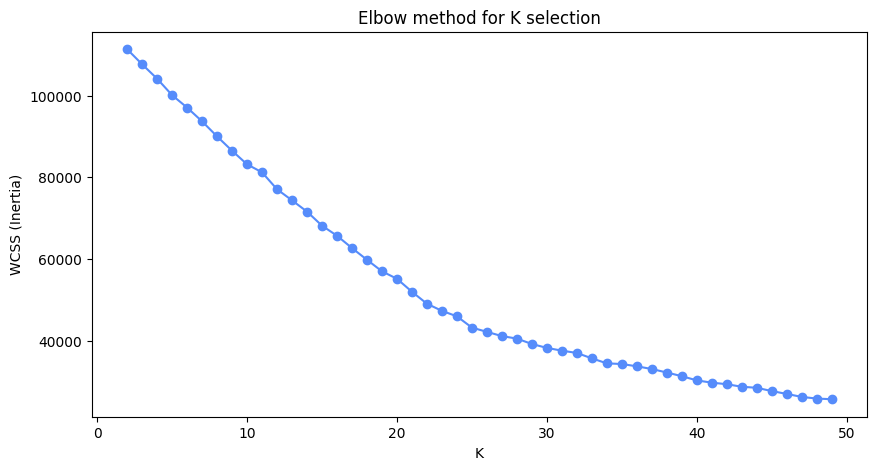

In [17]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

expanded_sessions = []
for visit_id, actions in sessions.items():
    for page, cat, ext_cat, topic, time in actions:
        if topic not in {"IN_GENERAL", "UNDETECTED", "NENI", "LASTMINUTE", ""}:
            expanded_sessions.append({
                'VisitID': visit_id,
                'TopicName': topic,
                'TimeOnPage': time
            })

df_flat = pd.DataFrame(expanded_sessions)

matrix = df_flat.pivot_table(
    index='VisitID',
    columns='TopicName',
    values='TimeOnPage',
    aggfunc='sum'
).fillna(0)

scaler = StandardScaler()
matrix_scaled = scaler.fit_transform(matrix)

wcss = []
k_range = range(2, min(50, len(matrix)))
for i in k_range:
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(matrix_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(k_range, wcss, marker='o')
plt.title('Elbow method for K selection')
plt.xlabel('K')
plt.ylabel('WCSS (Inertia)')
plt.show()


In [18]:
optimal_k = 25
model = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
clusters = model.fit_predict(matrix_scaled)

matrix['cluster'] = clusters

In [19]:
cluster_profiles = matrix.groupby('cluster').mean()
cluster_counts = matrix['cluster'].value_counts().sort_index()

#
for i in range(optimal_k):
    top_topics = cluster_profiles.loc[i].sort_values(ascending=False).head(5)
    top_topics = top_topics[top_topics > 15]
    count = cluster_counts[i]
    percentage = (count / len(matrix)) * 100

    print(f"\n--- Cluster {i} ---")
    print(f"Sessions count: {count} ({percentage:.1f}%)")
    print("Top 5 topics with avg time, filtered by min time=15 sec")
    print(top_topics)


--- Cluster 0 ---
Sessions count: 15 (0.3%)
Top 5 topics with avg time, filtered by min time=15 sec
TopicName
MONTENEGRO                        874.0
CHALLENGING_EXPEDITION             60.0
TOURS_WITH_LIGHTWEIGHT_TOURISM     44.0
STAYS_WITH_TRIPS                   42.0
TOURIST                            40.0
Name: 0, dtype: float64

--- Cluster 1 ---
Sessions count: 126 (2.5%)
Top 5 topics with avg time, filtered by min time=15 sec
TopicName
HIKING             710.952381
TOURISM             79.285714
ALPS                32.142857
VHT                 30.476190
CLIMBING_SCHOOL     25.714286
Name: 1, dtype: float64

--- Cluster 2 ---
Sessions count: 6 (0.1%)
Top 5 topics with avg time, filtered by min time=15 sec
TopicName
GOLF    550.0
SKI      85.0
Name: 2, dtype: float64

--- Cluster 3 ---
Sessions count: 174 (3.5%)
Top 5 topics with avg time, filtered by min time=15 sec
TopicName
TOURISM                           777.586207
TOURS_WITH_ACCOMMODATION           44.827586
HIKING         

### Write to mlflow

In [20]:
import os

outputs_dir = "../outputs"
os.makedirs(outputs_dir, exist_ok=True)

plt.figure(figsize=(10, 5))
plt.plot(k_range, wcss, marker='o')
plt.title('Elbow method for K selection')
plt.xlabel('K')
plt.ylabel('WCSS (Inertia)')

elbow_path = f"{outputs_dir}/elbow.png"
plt.savefig(elbow_path)
plt.close()

mlflow.log_artifact(elbow_path, artifact_path="clustering")

import json

cluster_summary = []

for i in range(optimal_k):
    top_topics = cluster_profiles.loc[i].sort_values(ascending=False).head(5)
    top_topics = top_topics[top_topics > 15]

    count = int(cluster_counts.get(i, 0))
    percentage = (count / len(matrix)) * 100

    cluster_summary.append({
        "cluster": i,
        "session_count": count,
        "percentage": percentage,
        "top_topics": {
            topic: float(value)
            for topic, value in top_topics.items()
        }
    })

cluster_file = f"{outputs_dir}/cluster_summary.json"
with open(cluster_file, "w", encoding="utf-8") as f:
    json.dump(cluster_summary, f, indent=2)

mlflow.log_artifact(cluster_file, artifact_path="clustering")


## Stop mlflow

In [21]:
mlflow.log_metric("total_run_duration", (datetime.now() - start_time).total_seconds())
mlflow.end_run()

🏃 View run merciful-trout-23 at: http://localhost:5000/#/experiments/1/runs/8332a68ebd3a4a81a2507c918963977a
🧪 View experiment at: http://localhost:5000/#/experiments/1
